In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa estudia invertir en una línea de envasado automatizada. Los datos del caso se adjuntan (importes en k€; precio y coste variable en € por unidad). La inversión se amortiza linealmente durante la vida del proyecto hasta su valor residual, que se recupera al final por su valor contable. El circulante necesario cada año es una fracción de las ventas de ese año, se aporta al principio del año (el del primer año, en el momento 0) y se recupera íntegramente al final.

In [4]:
pregunta_1 = "1. Construya la tabla de flujos de caja libre año a año: ventas, costes, EBITDA, amortización, BAI, impuesto, BDI y flujo de caja libre (FCL).  "
pregunta_2 = "2. Calcule el VAN a la tasa de descuento dada, mostrando el factor de descuento y el valor actual de cada flujo. ¿Es viable el proyecto?  "
pregunta_3 = "3. Calcule la TIR. ¿Cómo se interpreta frente a la tasa de descuento?  "
pregunta_4 = "4. Calcule el periodo de recuperación simple y el descontado. ¿Por qué el descontado es mayor? ¿Qué información da el payback que no dan el VAN ni la TIR, y cuál omite?  "
pregunta_5 = "5. ¿Qué supuesto del caso le parece más frágil? Compruebe cuánto cambia el VAN si las unidades del año 1 son un 15 % menores.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya la tabla de flujos de caja libre año a año: ventas, costes, EBITDA, amortización, BAI, impuesto, BDI y flujo de caja libre (FCL).  

2. Calcule el VAN a la tasa de descuento dada, mostrando el factor de descuento y el valor actual de cada flujo. ¿Es viable el proyecto?  

3. Calcule la TIR. ¿Cómo se interpreta frente a la tasa de descuento?  

4. Calcule el periodo de recuperación simple y el descontado. ¿Por qué el descontado es mayor? ¿Qué información da el payback que no dan el VAN ni la TIR, y cuál omite?  

5. ¿Qué supuesto del caso le parece más frágil? Compruebe cuánto cambia el VAN si las unidades del año 1 son un 15 % menores.  

In [5]:
#| tbl-cap: "Datos del caso"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  parametro                                              , valor
    ('inversión inicial (k€)'                               , 760  ),
    ('vida del proyecto (años)'                             , 7    ),
    ('precio (€ por miles de unidade)'                      , 3    ),
    ('miles de unidades vendidas el año 1'                  , 360  ),
    ('crecimiento anual de las unidades'                    , 0.05 ),
    ('coste variable unitario (€)'                          , 2    ),
    ('costes fijos anuales (k€)'                            , 100  ),
    ('valor residual al final (k€)'                         , 75   ),
    ('circulante necesario (fracción de las ventas del año)', 0.08 ),
    ('tipo impositivo'                                      , 0.25 ),
    ('tasa de descuento'                                    , 0.12 ),
], columns=['parametro', 'valor']).set_index('parametro')
datos_enunciado

,valor
parametro,
inversión inicial (k€),760.00
vida del proyecto (años),7.00
precio (€ por miles de unidade),3.00
miles de unidades vendidas el año 1,360.00
crecimiento anual de las unidades,0.05
coste variable unitario (€),2.00
costes fijos anuales (k€),100.00
valor residual al final (k€),75.00
circulante necesario (fracción de las ventas del año),0.08


# Resolución

In [6]:
def van(flujos, k):
    '''Valor actual neto de una lista de flujos (el primero en t = 0) a la tasa k.'''
    return float(sum(f / (1 + k) ** t for t, f in enumerate(flujos)))

def tir(flujos):
    '''Tasa que anula el VAN (por bisección entre −99 % y 1000 %).'''
    from scipy.optimize import brentq
    return float(brentq(lambda k: van(flujos, k), -0.99, 10.0))

def tabla_descuento(flujos, k):
    '''Año, flujo, factor de descuento, valor actual y valores acumulados (simple y descontado).'''
    t = pd.DataFrame({'flujo': list(flujos)}, index=pd.Index(range(len(flujos)), name='año'))
    t['(1 + k)^-t'] = [(1 + k) ** -i for i in t.index]
    t['valor actual'] = t['flujo'] * t['(1 + k)^-t']
    t['acumulado'] = t['flujo'].cumsum()
    t['acumulado descontado'] = t['valor actual'].cumsum()
    return t

def payback(flujos, k=None):
    '''Periodo de recuperación (años, con interpolación lineal dentro del año); descontado si se da k.'''
    acum = 0.0
    for t, f in enumerate(flujos):
        v = f if k is None else f / (1 + k) ** t
        if t > 0 and acum < 0 <= acum + v:
            return float(t - 1 + (-acum) / v)
        acum += v
    return float('inf')

def anualidad_equivalente(VAN, k, n):
    '''Anualidad constante durante n años cuyo valor actual es VAN.'''
    return float(VAN * k / (1 - (1 + k) ** -n))

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Construya la tabla de flujos de caja libre año a año: ventas, costes, EBITDA, amortización, BAI, impuesto, BDI y flujo de caja libre (FCL).  

Orden de cálculo, año a año (k€): ventas = unidades × precio; EBITDA = ventas − costes variables − costes fijos; BAI = EBITDA − amortización (lineal sobre inversión − valor residual); impuesto = tipo × BAI si BAI > 0; BDI = BAI − impuesto. El flujo de caja libre suma al BDI la amortización (no es un pago) y resta las inversiones en activo fijo y en circulante; en el último año se recuperan el circulante y el valor residual.

In [8]:
p = datos_enunciado['valor'].to_dict()
I0, n, precio = p['inversión inicial (k€)'], int(p['vida del proyecto (años)']), [v for c, v in p.items() if c.startswith('precio')][0]
u1 = [v for c, v in p.items() if 'año 1' in c][0]
g, cv, CF = p['crecimiento anual de las unidades'], p['coste variable unitario (€)'], p['costes fijos anuales (k€)']
VR, w, t_imp, k = p['valor residual al final (k€)'], p['circulante necesario (fracción de las ventas del año)'], p['tipo impositivo'], p['tasa de descuento']

In [9]:
#| tbl-cap: "Flujos de caja libre del proyecto (k€)"
#| label: tbl-flujos
anos = list(range(0, n + 1))
unidades = pd.Series([0] + [u1 * (1 + g) ** (t - 1) for t in range(1, n + 1)], index=anos)
ventas = unidades * precio
costes_variables = unidades * cv
costes_fijos = pd.Series([0] + [CF] * n, index=anos)
EBITDA = ventas - costes_variables - costes_fijos
amortizacion = pd.Series([0] + [(I0 - VR) / n] * n, index=anos)
BAI = EBITDA - amortizacion
impuesto = BAI.clip(lower=0) * t_imp; impuesto[0] = 0
BDI = BAI - impuesto
circulante = pd.Series([w * ventas[1]] + [w * ventas[t] for t in range(1, n + 1)], index=anos)   # el del año 1 se aporta en t = 0
variacion_circulante = circulante.diff().fillna(circulante[0]); variacion_circulante[n] -= circulante[n]   # se recupera al final
inversion = pd.Series([I0] + [0] * n, index=anos)
valor_residual = pd.Series([0] * n + [VR], index=anos)
FCL = BDI + amortizacion - variacion_circulante - inversion + valor_residual
tabla = pd.DataFrame({'unidades': unidades, 'ventas': ventas, 'costes variables': costes_variables, 'costes fijos': costes_fijos,
                      'EBITDA': EBITDA, 'amortización': amortizacion, 'BAI': BAI, 'impuesto': impuesto, 'BDI': BDI,
                      '+ amortización': amortizacion, '− Δ circulante': -variacion_circulante, '− inversión': -inversion,
                      '+ valor residual': valor_residual, 'FCL': FCL})
tabla.index.name = 'año'
flujos = FCL.tolist()
tabla.round(1).T

año,0,1,2,3,4,5,6,7
unidades,0.0,360.0,378.0,396.9,416.7,437.6,459.5,482.4
ventas,0.0,1080.0,1134.0,1190.7,1250.2,1312.7,1378.4,1447.3
costes variables,0.0,720.0,756.0,793.8,833.5,875.2,918.9,964.9
costes fijos,0.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
EBITDA,0.0,260.0,278.0,296.9,316.7,337.6,359.5,382.4
amortización,0.0,97.9,97.9,97.9,97.9,97.9,97.9,97.9
BAI,0.0,162.1,180.1,199.0,218.9,239.7,261.6,284.6
impuesto,0.0,40.5,45.0,49.8,54.7,59.9,65.4,71.1
BDI,0.0,121.6,135.1,149.3,164.2,179.8,196.2,213.4
+ amortización,0.0,97.9,97.9,97.9,97.9,97.9,97.9,97.9


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Calcule el VAN a la tasa de descuento dada, mostrando el factor de descuento y el valor actual de cada flujo. ¿Es viable el proyecto?  

In [11]:
#| tbl-cap: "Descuento de los flujos"
#| label: tbl-descuento
descuento = tabla_descuento(flujos, k)
descuento.round(2)

,flujo,(1 + k)^-t,valor actual,acumulado,acumulado descontado
año,,,,,
0,-846.40,1.00,-846.40,-846.40,-846.40
1,219.46,0.89,195.95,-626.94,-650.45
2,228.64,0.80,182.27,-398.29,-468.18
3,242.60,0.71,172.68,-155.69,-295.50
4,257.26,0.64,163.49,101.57,-132.00
5,272.65,0.57,154.71,374.22,22.71
6,288.81,0.51,146.32,663.03,169.03
7,496.56,0.45,224.62,1159.59,393.65


In [12]:
VAN = van(flujos, k)
Markdown(f'''VAN = Σ FCL_t / (1 + {k})^t = ''' + ' + '.join(f'{f:.1f}/{(1 + k) ** t:.3f}' for t, f in enumerate(flujos)) + f''' = **{VAN:.1f} k€**. {("Es positivo: el proyecto devuelve la inversión, remunera el capital al " + f"{k:.0%}" + " y además crea " + f"{VAN:.0f}" + " k€ de valor; es viable.") if VAN > 0 else "Es negativo: no es viable a esa tasa."}''')

VAN = Σ FCL_t / (1 + 0.12)^t = -846.4/1.000 + 219.5/1.120 + 228.6/1.254 + 242.6/1.405 + 257.3/1.574 + 272.7/1.762 + 288.8/1.974 + 496.6/2.211 = **393.6 k€**. Es positivo: el proyecto devuelve la inversión, remunera el capital al 12% y además crea 394 k€ de valor; es viable.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Calcule la TIR. ¿Cómo se interpreta frente a la tasa de descuento?  

In [14]:
TIR = tir(flujos)
comprobacion = van(flujos, TIR)
Markdown(f'TIR = {TIR:.2%} (VAN a esa tasa: {comprobacion:.4f} ≈ 0). Es la rentabilidad del proyecto; como supera la tasa de descuento ({k:.0%}), '
         'el VAN es positivo: las dos reglas coinciden en un proyecto aislado con flujos convencionales (un desembolso y luego cobros).')

TIR = 23.92% (VAN a esa tasa: -0.0000 ≈ 0). Es la rentabilidad del proyecto; como supera la tasa de descuento (12%), el VAN es positivo: las dos reglas coinciden en un proyecto aislado con flujos convencionales (un desembolso y luego cobros).

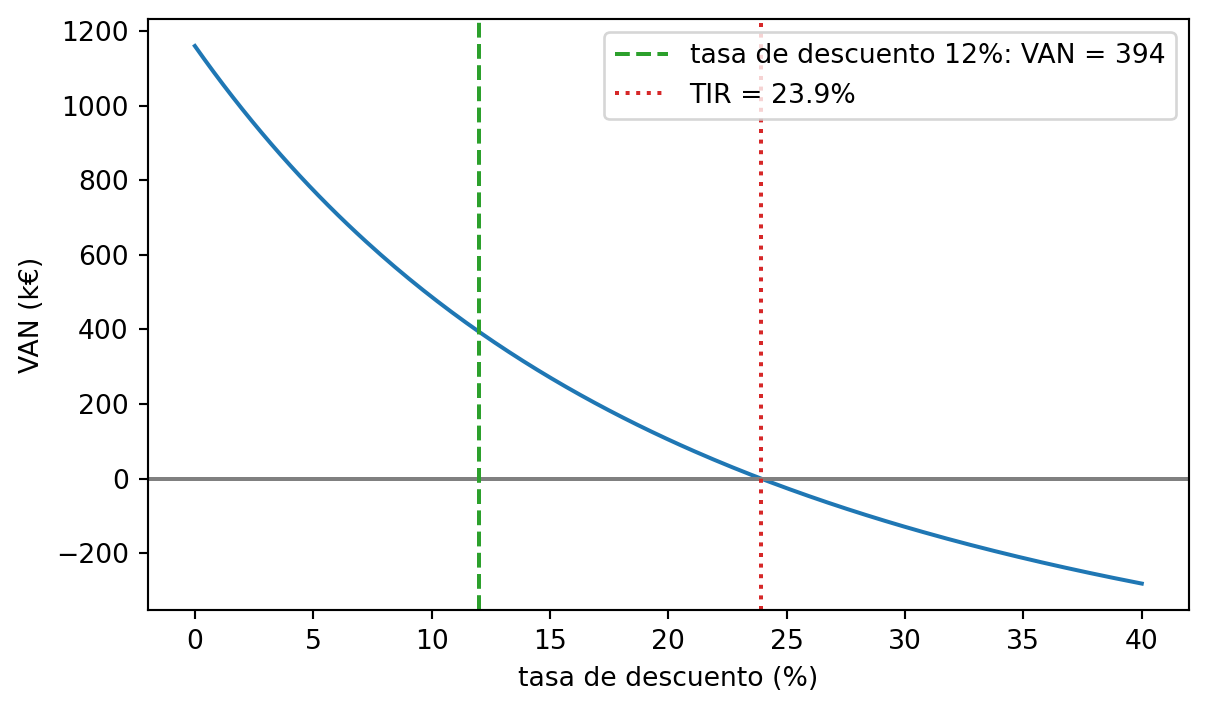

In [15]:
#| fig-cap: "Perfil del VAN frente a la tasa de descuento"
#| label: fig-perfil
from matplotlib import pyplot as plt
ks = np.linspace(0, max(0.4, TIR + 0.1), 200)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks * 100, [van(flujos, x) for x in ks]); ax.axhline(0, color='grey')
ax.axvline(k * 100, color='tab:green', linestyle='--', label=f'tasa de descuento {k:.0%}: VAN = {VAN:.0f}')
ax.axvline(TIR * 100, color='tab:red', linestyle=':', label=f'TIR = {TIR:.1%}')
ax.set_xlabel('tasa de descuento (%)'); ax.set_ylabel('VAN (k€)'); ax.legend(); plt.show()

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Calcule el periodo de recuperación simple y el descontado. ¿Por qué el descontado es mayor? ¿Qué información da el payback que no dan el VAN ni la TIR, y cuál omite?  

In [17]:
pb, pbd = payback(flujos), payback(flujos, k)
display(descuento[['flujo', 'acumulado', 'valor actual', 'acumulado descontado']].round(1))
Markdown(f'''Payback simple: el acumulado cambia de signo en el año {int(np.ceil(pb))}; interpolando, {pb:.2f} años. Payback descontado: {pbd:.2f} años (mayor, porque los flujos descontados son menores y tardan más en cubrir la inversión). El payback mide liquidez y riesgo de plazo (cuánto tiempo está el dinero expuesto), pero ignora los flujos posteriores a la recuperación y, en su versión simple, el valor del tiempo; por eso se usa como criterio complementario, nunca único.''')

,flujo,acumulado,valor actual,acumulado descontado
año,,,,
0,-846.4,-846.4,-846.4,-846.4
1,219.5,-626.9,196.0,-650.4
2,228.6,-398.3,182.3,-468.2
3,242.6,-155.7,172.7,-295.5
4,257.3,101.6,163.5,-132.0
5,272.7,374.2,154.7,22.7
6,288.8,663.0,146.3,169.0
7,496.6,1159.6,224.6,393.6


Payback simple: el acumulado cambia de signo en el año 4; interpolando, 3.61 años. Payback descontado: 4.85 años (mayor, porque los flujos descontados son menores y tardan más en cubrir la inversión). El payback mide liquidez y riesgo de plazo (cuánto tiempo está el dinero expuesto), pero ignora los flujos posteriores a la recuperación y, en su versión simple, el valor del tiempo; por eso se usa como criterio complementario, nunca único.

## Apartado 5

In [18]:
display(Markdown(pregunta_5))

5. ¿Qué supuesto del caso le parece más frágil? Compruebe cuánto cambia el VAN si las unidades del año 1 son un 15 % menores.  

In [19]:
u1_bajo = u1 * 0.85
def modelo(u1, precio, cv, CF, g=g, I0=I0, n=n, VR=VR, w=w, t_imp=t_imp):
    unidades = pd.Series([0] + [u1 * (1 + g) ** (t - 1) for t in range(1, n + 1)])
    ventas = unidades * precio; EBITDA = ventas - unidades * cv - pd.Series([0] + [CF] * n)
    amort = pd.Series([0] + [(I0 - VR) / n] * n); BAI = EBITDA - amort
    imp = BAI.clip(lower=0) * t_imp; imp[0] = 0
    circ = pd.Series([w * ventas[1]] + [w * ventas[t] for t in range(1, n + 1)])
    dcirc = circ.diff().fillna(circ[0]); dcirc[n] -= circ[n]
    return (BAI - imp + amort - dcirc - pd.Series([I0] + [0] * n) + pd.Series([0] * n + [VR])).tolist()
VAN_bajo = van(modelo(u1_bajo, precio, cv, CF), k)
Markdown(f'''Con un 15 % menos de unidades el VAN pasa de {VAN:.1f} a {VAN_bajo:.1f} k€ ({(VAN_bajo - VAN) / VAN:+.0%}): {"sigue siendo viable" if VAN_bajo > 0 else "deja de ser viable"}. Las unidades vendidas (y el precio) son el supuesto más frágil: son previsiones de mercado, mientras que la inversión y los costes fijos están casi cerrados por contrato.''')

Con un 15 % menos de unidades el VAN pasa de 393.6 a 191.1 k€ (-51%): sigue siendo viable. Las unidades vendidas (y el precio) son el supuesto más frágil: son previsiones de mercado, mientras que la inversión y los costes fijos están casi cerrados por contrato.